### Build a basic chatbot with langgraph (GRAPH API)

In [1]:
#cell 1
from typing import Annotated

from typing import TypedDict

from langgraph.graph import StateGraph,START,END

from langgraph.graph.message import add_messages       #these add_messages are called reducers  #pg.04

In [ ]:
#cell 2
class State(TypedDict):
    # Messages have the type "list". The'add_messages' function
    # in the.annotation .defines .how this .state .key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)

    messages:Annotated[list,add_messages]   

graph_builder=StateGraph(State)            #also in cell 08 but both are same

In [3]:
#cell 3
graph_builder

In [4]:
#cell 4

import os
from dotenv import load_dotenv
load_dotenv() 

True

In [5]:
#cell 5

from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")   #or llm=init_chat_model('groq:llama3-8b-8192')


In [6]:
#cell 6
llm


ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.5', 'langchain': '1.4.2'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001F1856BEBA0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F1856BF8C0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
#cell 7  this is node functionality

def chatbot(state:State):
    return{"messages":[llm.invoke(state["messages"])]}

In [ ]:
#cell 8

graph_builder=StateGraph(State)  #same ,but for explanation see pg 5

In [ ]:
#cell 8

graph_builder.add_node("llmchatbot",chatbot)             #(llm's name, node definition (def function which tells the function of the node) ))

graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge('llmchatbot',END)

graph=graph_builder.compile()

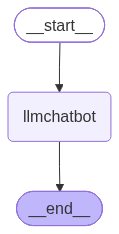

In [10]:
#cell 9

#visualise the graph

from IPython.display import Image, display


display(Image(graph.get_graph().draw_mermaid_png()))



PNG generated: True
PNG size: 6071 bytes


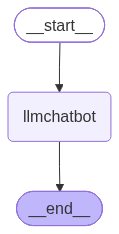

In [ ]:
#chat gpt code
from IPython.display import Image, display

png_data = graph.get_graph().draw_mermaid_png()

print("PNG generated:", isinstance(png_data, bytes))
print("PNG size:", len(png_data), "bytes")

display(Image(data=png_data))

In [20]:
#cell 10

r=graph.invoke({"messages":"what are you?"})
print(r["messages"][-1].content,"\n")
print(r)

I’m ChatGPT, a large language model created by OpenAI. I’m designed to understand and generate natural‑language text, so I can answer questions, help with writing, explain concepts, and chat about a wide range of topics. I don’t have a physical form or personal experiences—everything I say is generated from patterns in the data I was trained on. 

{'messages': [HumanMessage(content='what are you?', additional_kwargs={}, response_metadata={}, id='3af8aa76-d794-41da-a546-a0e1cf16c846'), AIMessage(content='I’m ChatGPT, a large language model created by OpenAI. I’m designed to understand and generate natural‑language text, so I can answer questions, help with writing, explain concepts, and chat about a wide range of topics. I don’t have a physical form or personal experiences—everything I say is generated from patterns in the data I was trained on.', additional_kwargs={'reasoning_content': 'The user: "what are you?" They are asking about the assistant. We need to answer: I am ChatGPT, a la

In [26]:
#cell 11
#streaming and get only ai response

for event in graph.stream({"messages":"can you sing a song"}):
    print("1->",event,"\n")
    for values in event.values():
        print("2->",values,"\n")
        print("3->",values["messages"][-1].content)

1-> {'llmchatbot': {'messages': [AIMessage(content='I’m not able to produce actual sound, but I can definitely give you a little “song” you can sing yourself or read along.  \nHere’s a short, upbeat original piece about chasing a dream—feel free to add your own melody!\n\n---\n\n**Title: “Catch the Light”**\n\n*(Verse 1)*  \nWoke up to the sunrise, painting streets in gold,  \nCoffee in my pocket, stories waiting to be told.  \nEvery step I take is a beat inside my heart,  \nI’m chasing something brighter, a brand‑new start.\n\n*(Pre‑Chorus)*  \nThe world’s a canvas, and I’m the hand that paints,  \nWith every line I write, I break the old constraints.\n\n*(Chorus)*  \nCatch the light, feel the fire in your soul,  \nHold on tight, let the rhythm take control.  \nDreams are the wings that lift us up above,  \nWe’re flying high, guided by our own love.\n\n*(Verse 2)*  \nFootsteps echo on the pavement, every sound a drum,  \nI hear the whispers of tomorrow, calling out my name.  \nThe dou

***LLM With Tool*** -tavily

In [6]:
#cell 12
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY")

from langchain_tavily import TavilySearch

tool=TavilySearch(max_result=2)
tool.invoke("what is language")

{'query': 'what is language',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.britannica.com/topic/language',
   'title': 'Language | Definition, Types, Characteristics, Development, & Facts | Britannica',
   'content': 'What is language?\n\n  Language is a system of communication that uses conventional symbols, whether spoken, signed, or written. It allows people to express themselves as members of a social group and participants in its culture. The functions of language include communication, expressing identity, imaginative expression, play, and emotional release. [...] Language is a communication system using symbols to express ideas, feelings, and influence others. It facilitates the sharing of information, beliefs, attitudes, and emotions, creating a common history and life experience.\n\n  People use language to express identity, and it also has playful and imaginative functions seen in puns, poetry, and religious expression. Thoug

In [ ]:
#cell 13


In [ ]:
#cell 14